# 04 · Joint Training of the Text and Graph Encoders

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows: avoid the duplicate-OpenMP abort that kills the kernel
import faulthandler; faulthandler.enable()          # prints a native traceback to the Jupyter log if the kernel dies
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
from cmucl_nb import common as C, views as V

cfg = C.load_config(); args = C.as_args(cfg); device = C.get_device(cfg)
C.set_cpu_threads()                          # leave some CPU cores free so the laptop stays responsive
C.fetch_official_code()                      # official repo -> ./third_party/CMUCL (not copied into this repo)
from model import CMUCL, tokenize            # official model + tokenizer
from data import DataHelper                  # official neighbour sampler

ds = C.load_saved_dataset()
x = torch.from_numpy(ds["feats"]).to(device)
edge_index = torch.from_numpy(ds["edge_index"]).to(device)
labels, texts = ds["labels"], ds["texts"]
print(f"dataset={cfg['dataset']}  device={device}  torch threads={torch.get_num_threads()}  nodes={ds['n']} (of {cfg.get('n_full')})  anomalies={labels.sum()}")

dataset=Citeseer  device=cpu  torch threads=4  nodes=576 (of 3186)  anomalies=23


In [2]:
MAX_BATCHES = int(os.environ.get("CMUCL_MAX_BATCHES", 0)) or None
model = CMUCL(args).to(device); C.prepare_model(model)   # CPU: thread limit + gradient checkpointing (same maths, far less RAM)
model.load_state_dict(torch.load(C.ART / "init_state.pt", map_location=device))
probe = V.load_probe(C.ART, texts, tokenize, args.context_length, device)
Data = DataHelper(ds["edge_index"], args)
anom_pos = np.where(labels[probe[0].numpy()] == 1)[0]

history = dict(batch_loss=[], epoch_bounds=[], probe=[]); cos_snap = {}
def probe_eval(tag):
    model.eval(); _, lg = V.probe_logits(model, x, edge_index, probe, args.neigh_num); sc = float(model.logit_scale.exp())
    Lv = V.view_losses(lg); history["probe"].append(dict(tag=tag, tau=1 / sc, **{k: float(v) for k, v in Lv.items()}))
    cos_snap[tag] = {k: (lg[k] / sc).cpu().numpy() for k in lg}; model.train()
probe_eval("init")
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, "M")

lenth of dataset 576
trainable parameters: 63.504002 M


C:\Users\KimiaMalekizadeh\AppData\Local\Temp\ipykernel_1948\3171795102.py:10: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  model.eval(); _, lg = V.probe_logits(model, x, edge_index, probe, args.neigh_num); sc = float(model.logit_scale.exp())


In [3]:
avail = C.ram_available_gb()
if avail is not None:
    print(f"available RAM: {avail:.1f} GB")
    assert avail > 3.5, "Less than ~3.5 GB RAM free: close other programs, or set CMUCL_BATCH_SIZE=32 (NOT the official setting) and re-run notebook 00."
C.setup_seed(cfg["seed"]); model.train(); t0 = time.time()
for ep in range(args.epoch_num):
    loader = DataLoader(Data, batch_size=args.batch_size, shuffle=True, num_workers=0)
    for ib, sb in enumerate(loader):
        if MAX_BATCHES and ib >= MAX_BATCHES: break
        s_n, t_n = sb["s_n"], sb["t_n"]
        s_text = tokenize(texts[s_n.numpy()].tolist(), context_length=args.context_length).to(device)
        t_text = tokenize(texts[t_n.numpy().reshape(-1)].tolist(), context_length=args.context_length).to(device)
        loss = model.forward(x, edge_index, s_n, t_n, s_text, t_text, ep, device)      # official: loss.backward() + Adam step inside
        history["batch_loss"].append(loss)
        if ib % 5 == 0 or ib == len(loader) - 1: print(f"epoch {ep} batch {ib}/{len(loader)} loss {loss:.4f}  ({time.time()-t0:.0f}s)")
    history["epoch_bounds"].append(len(history["batch_loss"])); probe_eval(f"epoch {ep+1}")
    print(f"epoch {ep} finished, last loss {loss:.4f}")
print(f"Pre-training finished in {time.time()-t0:.0f}s")

available RAM: 4.7 GB
epoch 0 batch 0/9 loss 18.1085  (88s)
epoch 0 batch 5/9 loss 17.0777  (557s)
epoch 0 batch 8/9 loss 16.9521  (836s)
epoch 0 finished, last loss 16.9521
epoch 1 batch 0/9 loss 16.7457  (956s)
epoch 1 batch 5/9 loss 15.3128  (1406s)
epoch 1 batch 8/9 loss 13.8294  (1646s)
epoch 1 finished, last loss 13.8294
Pre-training finished in 1667s


<div dir="rtl" style="text-align:right">

## منحنی loss و loss هر view روی probe batch ثابت

</div>

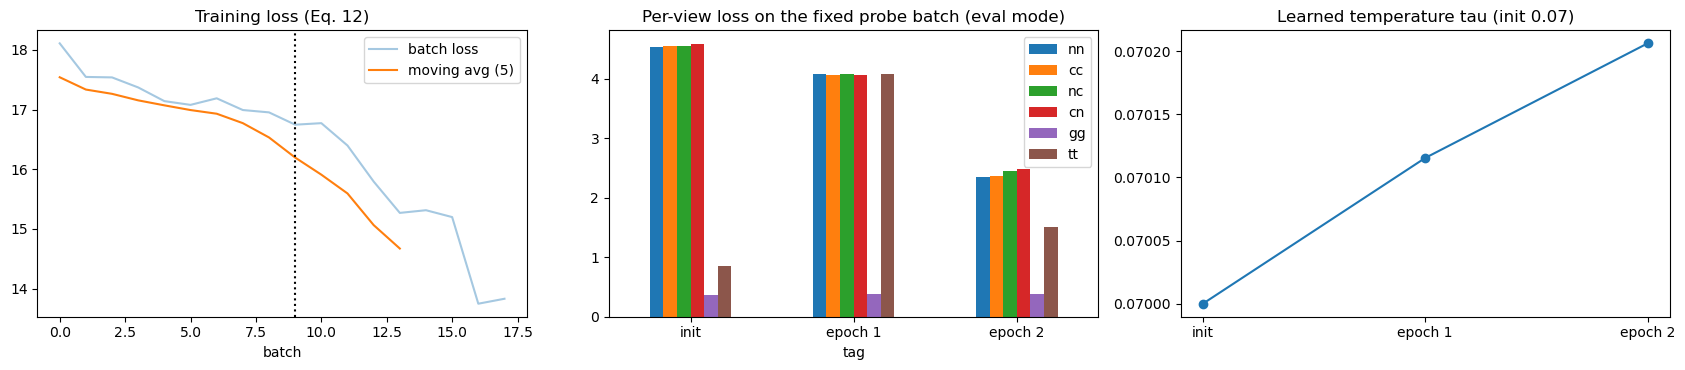

,nn,cc,nc,cn,gg,tt
tag,,,,,,
init,4.5230,4.5396,4.5500,4.5820,0.3631,0.8566
epoch 1,4.0692,4.0526,4.0804,4.0604,0.3801,4.0787
epoch 2,2.3554,2.3560,2.4528,2.4800,0.3882,1.5065


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
bl = np.array(history["batch_loss"]); ax[0].plot(bl, alpha=.4, label="batch loss")
if len(bl) > 5: ax[0].plot(np.convolve(bl, np.ones(5) / 5, mode="valid"), label="moving avg (5)")
for b in history["epoch_bounds"][:-1]: ax[0].axvline(b, color="k", ls=":")
ax[0].set_title("Training loss (Eq. 12)"); ax[0].set_xlabel("batch"); ax[0].legend()
P = pd.DataFrame(history["probe"]).set_index("tag")[list(V.VIEW_INFO)]
P.plot.bar(ax=ax[1]); ax[1].set_title("Per-view loss on the fixed probe batch (eval mode)"); ax[1].tick_params(axis="x", rotation=0)
ax[2].plot([h["tau"] for h in history["probe"]], marker="o"); ax[2].set_xticks(range(len(history["probe"]))); ax[2].set_xticklabels([h["tag"] for h in history["probe"]])
ax[2].set_title("Learned temperature tau (init 0.07)")
plt.tight_layout(); C.savefig("04_training_curves"); plt.show()
display(P.round(4))

<div dir="rtl" style="text-align:right">

## قبل و بعد از آموزش: همان probe batch، همان گره‌ها

</div>

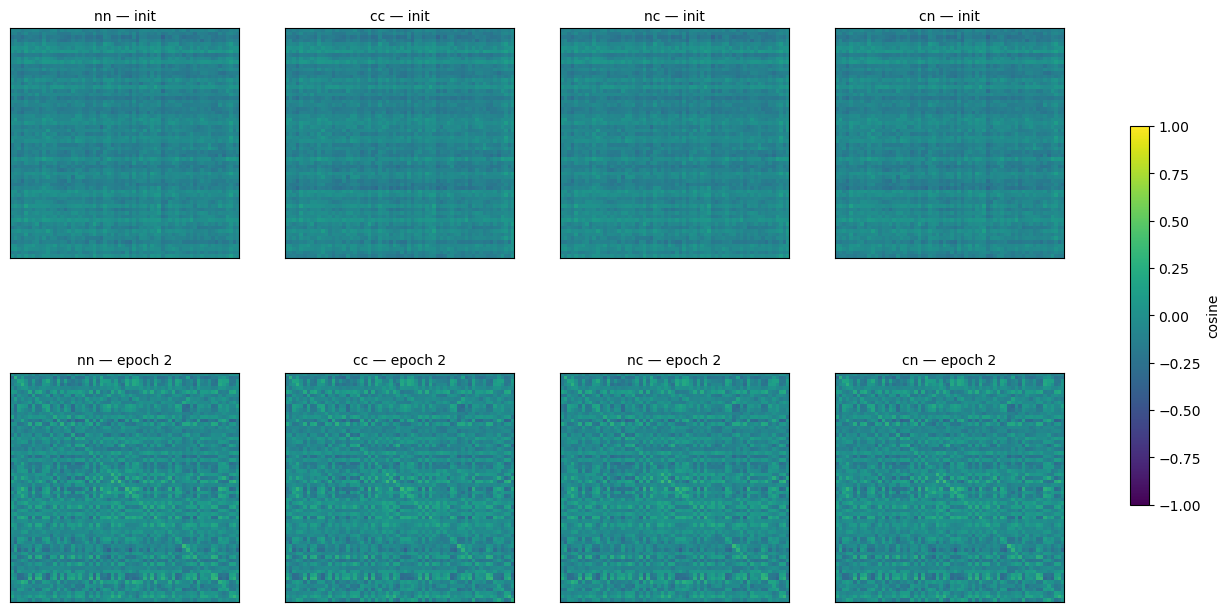

nn init     mean diag -0.083 | mean off-diag -0.082
nn epoch 2  mean diag +0.184 | mean off-diag -0.039
cc init     mean diag -0.085 | mean off-diag -0.084
cc epoch 2  mean diag +0.178 | mean off-diag -0.041
nc init     mean diag -0.085 | mean off-diag -0.082
nc epoch 2  mean diag +0.174 | mean off-diag -0.040
cn init     mean diag -0.089 | mean off-diag -0.085
cn epoch 2  mean diag +0.172 | mean off-diag -0.040


In [5]:
last = f"epoch {len(history['epoch_bounds'])}"
fig, ax = plt.subplots(2, 4, figsize=(17, 8.2))
for r, tag in enumerate(["init", last]):
    for c, k in enumerate(V.CROSS):
        im = ax[r, c].imshow(cos_snap[tag][k], cmap="viridis", vmin=-1, vmax=1); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        ax[r, c].set_title(f"{k} — {tag}", fontsize=10)
fig.colorbar(im, ax=ax, shrink=.6, label="cosine"); C.savefig("04_before_after_matrices"); plt.show()
for k in V.CROSS:
    for tag in ["init", last]:
        M = cos_snap[tag][k]; print(f"{k:2s} {tag:8s} mean diag {np.diag(M).mean():+.3f} | mean off-diag {M[~np.eye(len(M), dtype=bool)].mean():+.3f}")

In [6]:
torch.save(model.state_dict(), C.ART / "trained_state.pt")
json.dump(history, open(C.ART / "history.json", "w"))
print("saved trained_state.pt + history.json")

saved trained_state.pt + history.json
